# PRCE-003 Mall Customers Analysis using PySpark

**Task 1:** Load the data in PySpark  
**Task 2:** Write an analysis report on the basis of the spending score

Dataset: Mall_Customers.csv (200 customers with Gender, Age, Annual Income and Spending Score)

 ## Step 1: Install and import PySpark

In [3]:
# install pyspark
!pip install pyspark

In [4]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, avg, min, max, round

# create spark session
spark = SparkSession.builder.appName("MallCustomers").getOrCreate()
spark

## Step 2: Load the dataset (Task 1)

In [6]:
# download the Mall_Customers.csv file from my GitHub repository
url = "https://raw.githubusercontent.com/vinithmadanu/Mall_Customers_Analysis/main/Mall_Customers.csv"
!wget -q -O Mall_Customers.csv "$url"

# read the csv file
df = spark.read.csv("Mall_Customers.csv", header=True, inferSchema=True)

# show first 10 rows
df.show(10)

+----------+------+---+------------------+----------------------+
|CustomerID| Genre|Age|Annual Income (k$)|Spending Score (1-100)|
+----------+------+---+------------------+----------------------+
|         1|  Male| 19|                15|                    39|
|         2|  Male| 21|                15|                    81|
|         3|Female| 20|                16|                     6|
|         4|Female| 23|                16|                    77|
|         5|Female| 31|                17|                    40|
|         6|Female| 22|                17|                    76|
|         7|Female| 35|                18|                     6|
|         8|Female| 23|                18|                    94|
|         9|  Male| 64|                19|                     3|
|        10|Female| 30|                19|                    72|
+----------+------+---+------------------+----------------------+
only showing top 10 rows


In [7]:
# check the columns and data types
df.printSchema()

root
 |-- CustomerID: integer (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Annual Income (k$): integer (nullable = true)
 |-- Spending Score (1-100): integer (nullable = true)



In [8]:
# number of rows and columns
print("Number of rows:", df.count())
print("Number of columns:", len(df.columns))
print("Columns:", df.columns)

Number of rows: 200
Number of columns: 5
Columns: ['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


## Step 3: Rename columns

Column names like "Annual Income (k$)" have spaces and brackets, so I renamed them to make them easy to use. The column "Genre" actually has Male/Female values so I renamed it to Gender.

In [9]:
df = df.withColumnRenamed("CustomerID", "CustomerId") \
       .withColumnRenamed("Genre", "Gender") \
       .withColumnRenamed("Annual Income (k$)", "Income") \
       .withColumnRenamed("Spending Score (1-100)", "SpendingScore")

df.show(5)

+----------+------+---+------+-------------+
|CustomerId|Gender|Age|Income|SpendingScore|
+----------+------+---+------+-------------+
|         1|  Male| 19|    15|           39|
|         2|  Male| 21|    15|           81|
|         3|Female| 20|    16|            6|
|         4|Female| 23|    16|           77|
|         5|Female| 31|    17|           40|
+----------+------+---+------+-------------+
only showing top 5 rows


## Step 4: Check for missing values and duplicates

In [10]:
# count null values in each column
for c in df.columns:
    print(c, ":", df.filter(col(c).isNull()).count())

CustomerId : 0
Gender : 0
Age : 0
Income : 0
SpendingScore : 0


In [11]:
# check duplicate rows
print("Total rows:", df.count())
print("Rows after removing duplicates:", df.dropDuplicates().count())

Total rows: 200
Rows after removing duplicates: 200


There are no missing values and no duplicate rows, so no cleaning is needed.

In [12]:
## Step 5: Basic statistics

In [13]:
# describe() gives count, mean, stddev, min and max
df.describe().show()

+-------+------------------+------+-----------------+-----------------+------------------+
|summary|        CustomerId|Gender|              Age|           Income|     SpendingScore|
+-------+------------------+------+-----------------+-----------------+------------------+
|  count|               200|   200|              200|              200|               200|
|   mean|             100.5|  NULL|            38.85|            60.56|              50.2|
| stddev|57.879184513951124|  NULL|13.96900733155888|26.26472116527124|25.823521668370173|
|    min|                 1|Female|               18|               15|                 1|
|    max|               200|  Male|               70|              137|                99|
+-------+------------------+------+-----------------+-----------------+------------------+



In [14]:
# statistics of spending score only
df.select(
    min("SpendingScore").alias("Min Score"),
    max("SpendingScore").alias("Max Score"),
    round(avg("SpendingScore"), 2).alias("Average Score")
).show()

+---------+---------+-------------+
|Min Score|Max Score|Average Score|
+---------+---------+-------------+
|        1|       99|         50.2|
+---------+---------+-------------+



## Step 6: Spending score analysis (Task 2)

### 6.1 Divide customers into spending groups
- Low: score 1 to 33
- Medium: score 34 to 66
- High: score 67 to 100

In [15]:
df = df.withColumn("SpendingGroup",
                   when(col("SpendingScore") <= 33, "Low")
                   .when(col("SpendingScore") <= 66, "Medium")
                   .otherwise("High"))

df.groupBy("SpendingGroup").count().orderBy("count").show()

+-------------+-----+
|SpendingGroup|count|
+-------------+-----+
|          Low|   49|
|         High|   57|
|       Medium|   94|
+-------------+-----+



In [16]:
# average age and income of each spending group
df.groupBy("SpendingGroup").agg(
    count("*").alias("Customers"),
    round(avg("Age"), 1).alias("Avg Age"),
    round(avg("Income"), 1).alias("Avg Income")
).show()

+-------------+---------+-------+----------+
|SpendingGroup|Customers|Avg Age|Avg Income|
+-------------+---------+-------+----------+
|         High|       57|   30.2|      66.1|
|          Low|       49|   42.9|      67.0|
|       Medium|       94|   42.0|      53.9|
+-------------+---------+-------+----------+



### 6.2 Spending score by gender

In [19]:
df.groupBy("Gender").agg(
    count("*").alias("Customers"),
    round(avg("SpendingScore"), 2).alias("Avg Spending Score")
).show()

+------+---------+------------------+
|Gender|Customers|Avg Spending Score|
+------+---------+------------------+
|Female|      112|             51.53|
|  Male|       88|             48.51|
+------+---------+------------------+



### 6.3 Spending score by age group

In [20]:
df = df.withColumn("AgeGroup",
                   when(col("Age") <= 30, "18-30")
                   .when(col("Age") <= 45, "31-45")
                   .when(col("Age") <= 60, "46-60")
                   .otherwise("60+"))

df.groupBy("AgeGroup").agg(
    count("*").alias("Customers"),
    round(avg("SpendingScore"), 2).alias("Avg Spending Score")
).orderBy("AgeGroup").show()

+--------+---------+------------------+
|AgeGroup|Customers|Avg Spending Score|
+--------+---------+------------------+
|   18-30|       62|             61.03|
|   31-45|       72|             52.57|
|   46-60|       49|              35.1|
|     60+|       17|             44.18|
+--------+---------+------------------+



### 6.4 Spending score by income group

In [21]:
df = df.withColumn("IncomeGroup",
                   when(col("Income") < 40, "Low Income")
                   .when(col("Income") <= 70, "Middle Income")
                   .otherwise("High Income"))

df.groupBy("IncomeGroup").agg(
    count("*").alias("Customers"),
    round(avg("SpendingScore"), 2).alias("Avg Spending Score")
).show()

+-------------+---------+------------------+
|  IncomeGroup|Customers|Avg Spending Score|
+-------------+---------+------------------+
|Middle Income|       80|             50.48|
|  High Income|       74|             50.19|
|   Low Income|       46|             49.74|
+-------------+---------+------------------+



### 6.5 Top 10 and lowest 10 spenders

In [22]:
print("Top 10 customers by spending score")
df.orderBy(col("SpendingScore").desc()).show(10)

Top 10 customers by spending score
+----------+------+---+------+-------------+-------------+--------+-----------+
|CustomerId|Gender|Age|Income|SpendingScore|SpendingGroup|AgeGroup|IncomeGroup|
+----------+------+---+------+-------------+-------------+--------+-----------+
|        12|Female| 35|    19|           99|         High|   31-45| Low Income|
|        20|Female| 35|    23|           98|         High|   31-45| Low Income|
|       146|  Male| 28|    77|           97|         High|   18-30|High Income|
|       186|  Male| 30|    99|           97|         High|   18-30|High Income|
|       128|  Male| 40|    71|           95|         High|   31-45|High Income|
|       168|Female| 33|    86|           95|         High|   31-45|High Income|
|         8|Female| 23|    18|           94|         High|   18-30| Low Income|
|       142|  Male| 32|    75|           93|         High|   31-45|High Income|
|       164|Female| 31|    81|           93|         High|   31-45|High Income|
|    

In [23]:
print("Lowest 10 customers by spending score")
df.orderBy(col("SpendingScore").asc()).show(10)

Lowest 10 customers by spending score
+----------+------+---+------+-------------+-------------+--------+-----------+
|CustomerId|Gender|Age|Income|SpendingScore|SpendingGroup|AgeGroup|IncomeGroup|
+----------+------+---+------+-------------+-------------+--------+-----------+
|       157|  Male| 37|    78|            1|          Low|   31-45|High Income|
|       159|  Male| 34|    78|            1|          Low|   31-45|High Income|
|         9|  Male| 64|    19|            3|          Low|     60+| Low Income|
|        31|  Male| 60|    30|            4|          Low|   46-60| Low Income|
|        33|  Male| 53|    33|            4|          Low|   46-60| Low Income|
|       135|  Male| 20|    73|            5|          Low|   18-30|High Income|
|       163|  Male| 19|    81|            5|          Low|   18-30|High Income|
|       141|Female| 57|    75|            5|          Low|   46-60|High Income|
|        23|Female| 46|    25|            5|          Low|   46-60| Low Income|
| 

### 6.6 High income customers with low spending score

In [24]:
# these customers have money but are not spending much
df.filter((col("Income") > 70) & (col("SpendingScore") < 40)).show()
print("Count:", df.filter((col("Income") > 70) & (col("SpendingScore") < 40)).count())

+----------+------+---+------+-------------+-------------+--------+-----------+
|CustomerId|Gender|Age|Income|SpendingScore|SpendingGroup|AgeGroup|IncomeGroup|
+----------+------+---+------+-------------+-------------+--------+-----------+
|       127|  Male| 43|    71|           35|       Medium|   31-45|High Income|
|       129|  Male| 59|    71|           11|          Low|   46-60|High Income|
|       131|  Male| 47|    71|            9|          Low|   46-60|High Income|
|       133|Female| 25|    72|           34|       Medium|   18-30|High Income|
|       135|  Male| 20|    73|            5|          Low|   18-30|High Income|
|       137|Female| 44|    73|            7|          Low|   31-45|High Income|
|       139|  Male| 19|    74|           10|          Low|   18-30|High Income|
|       141|Female| 57|    75|            5|          Low|   46-60|High Income|
|       145|  Male| 25|    77|           12|          Low|   18-30|High Income|
|       147|  Male| 48|    77|          

### 6.7 Correlation

In [26]:
# value near 1 = positive relation, near -1 = negative relation, near 0 = no relation
age_corr = df.corr("Age", "SpendingScore")
income_corr = df.corr("Income", "SpendingScore")

print("Correlation between Age and Spending Score:", age_corr)
print("Correlation between Income and Spending Score:", income_corr)

Correlation between Age and Spending Score: -0.32722684603909025
Correlation between Income and Spending Score: 0.009902848094037497


### 6.8 Using Spark SQL

In [27]:
df.createOrReplaceTempView("customers")

spark.sql("""
SELECT Gender, SpendingGroup, COUNT(*) AS Customers
FROM customers
GROUP BY Gender, SpendingGroup
ORDER BY Gender, SpendingGroup
""").show()

+------+-------------+---------+
|Gender|SpendingGroup|Customers|
+------+-------------+---------+
|Female|         High|       33|
|Female|          Low|       25|
|Female|       Medium|       54|
|  Male|         High|       24|
|  Male|          Low|       24|
|  Male|       Medium|       40|
+------+-------------+---------+



## Step 7: Graphs

In [28]:
import matplotlib.pyplot as plt

# convert to pandas for plotting (dataset is small so it is ok)
pdf = df.toPandas()

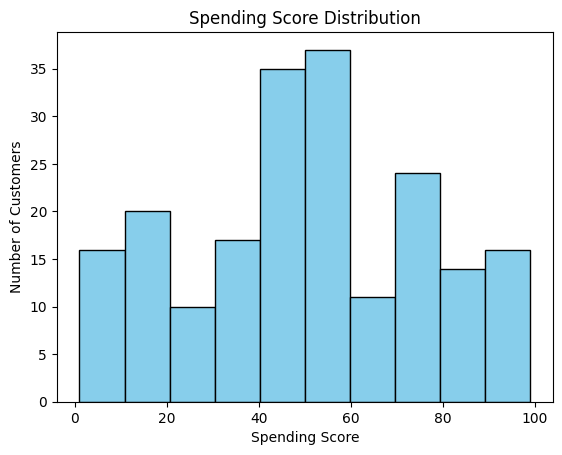

In [29]:
# histogram of spending score
plt.hist(pdf["SpendingScore"], bins=10, color="skyblue", edgecolor="black")
plt.title("Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")
plt.show()

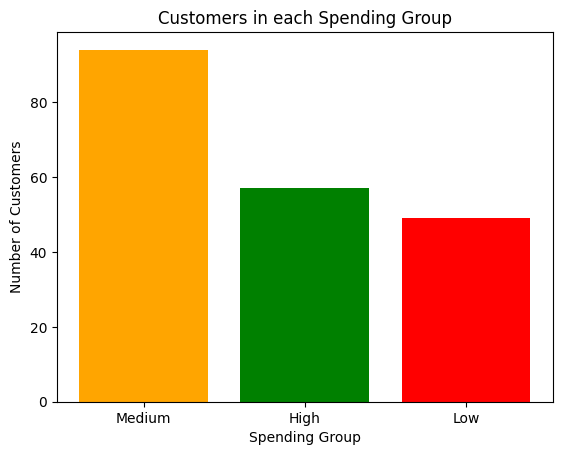

In [30]:
# number of customers in each spending group
group_counts = pdf["SpendingGroup"].value_counts()
plt.bar(group_counts.index, group_counts.values, color=["orange", "green", "red"])
plt.title("Customers in each Spending Group")
plt.xlabel("Spending Group")
plt.ylabel("Number of Customers")
plt.show()

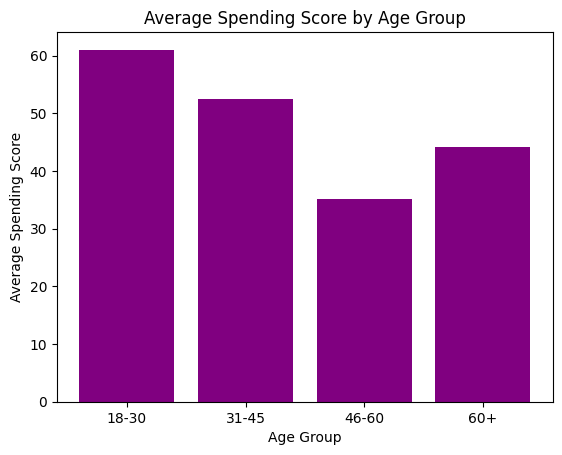

In [31]:
# average spending score by age group
age_avg = pdf.groupby("AgeGroup")["SpendingScore"].mean()
plt.bar(age_avg.index, age_avg.values, color="purple")
plt.title("Average Spending Score by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Spending Score")
plt.show()

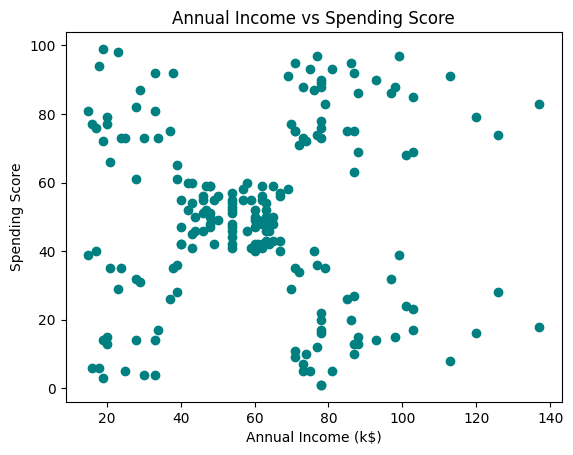

In [32]:
# income vs spending score
plt.scatter(pdf["Income"], pdf["SpendingScore"], color="teal")
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.show()

## Step 8: Conclusion

- The dataset has 200 customers and there were no missing values or duplicates.
- The average spending score is about 50. Most customers (94) are in the Medium spending group, 57 are High and 49 are Low.
- Younger customers (18-30) have the highest average spending score. Customers aged 46-60 spend the least.
- Female customers have a slightly higher average spending score than male customers.
- Age has a negative correlation with spending score (about -0.33), so older customers spend a little less.
- Income has almost no correlation with spending score (about 0.01). But the scatter plot shows that high income customers are divided into two groups: some spend a lot and some spend very little.
- The high income, low spending customers can be targeted with offers to make them spend more.

In [33]:
spark.stop()